# 6장 데이터 분석 실습 : sales_data.csv

## 1차시 : 데이터를 열어 보고, 믿을 수 있는지 확인

### [실습 1] 데이터 로딩 (11쪽)

In [1]:
import pandas as pd

df = pd.read_csv("sales_data.csv")
df.shape

(1030, 14)

In [2]:
df.head()

,order_date,shipping_date,delivery_date,region,category,product_id,quantity,unit_price,customer_id,customer_age,customer_gender,satisfaction,status,total_sales
0,2023-01-01,2023-01-04,2023-01-03,부산,전자제품,2772,61,34977.69,327,67.0,M,1.0,배송중,2133639.09
1,2023-01-02,2023-01-06,2023-01-04,부산,식품,3780,64,312589.27,318,34.0,M,4.0,배송완료,20005713.28
2,2023-01-03,2023-01-04,2023-01-05,부산,의류,8423,5,111813.88,297,50.0,F,4.0,배송완료,559069.40
3,2023-01-04,2023-01-07,2023-01-10,대구,식품,3871,53,297971.54,479,61.0,M,5.0,배송완료,15792491.62
4,2023-01-05,2023-01-08,2023-01-10,서울,식품,1660,55,65058.60,499,60.0,F,2.0,배송중,3578223.00


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_date       1030 non-null   str    
 1   shipping_date    1030 non-null   str    
 2   delivery_date    1025 non-null   str    
 3   region           1030 non-null   str    
 4   category         1030 non-null   str    
 5   product_id       1030 non-null   int64  
 6   quantity         1030 non-null   int64  
 7   unit_price       1030 non-null   float64
 8   customer_id      1030 non-null   int64  
 9   customer_age     979 non-null    float64
 10  customer_gender  1030 non-null   str    
 11  satisfaction     1000 non-null   float64
 12  status           1030 non-null   str    
 13  total_sales      1030 non-null   float64
dtypes: float64(4), int64(3), str(7)
memory usage: 112.8 KB


In [4]:
df.describe()

,product_id,quantity,unit_price,customer_id,customer_age,satisfaction,total_sales
count,1030.000000,1030.000000,1030.000000,1030.000000,979.000000,1000.000000,1.030000e+03
mean,5365.692233,65.134951,248893.777214,240.780583,44.858018,2.956000,1.235946e+07
std,2557.264515,113.597931,139497.370968,147.105954,14.253807,1.458146,1.065892e+07
min,1002.000000,1.000000,10455.410000,1.000000,20.000000,1.000000,2.376040e+04
25%,3292.500000,25.000000,129378.125000,107.000000,32.000000,2.000000,3.456833e+06
50%,5191.500000,50.000000,247732.410000,234.500000,45.000000,3.000000,9.425458e+06
75%,7581.250000,75.000000,369780.650000,368.750000,57.000000,4.000000,1.920825e+07
max,9996.000000,990.000000,498783.880000,499.000000,69.000000,5.000000,4.688031e+07


### [실습 2] 품질 점검 (16~19쪽)

In [5]:
df.isnull().sum()   # 완전성 : 칸마다 빈 곳의 수

order_date          0
shipping_date       0
delivery_date       5
region              0
category            0
product_id          0
quantity            0
unit_price          0
customer_id         0
customer_age       51
customer_gender     0
satisfaction       30
status              0
total_sales         0
dtype: int64

In [6]:
print(df.duplicated().sum())   # 일관성 : 완전히 같은 줄의 수

26


In [7]:
calc = df["quantity"] * df["unit_price"]
diff = (df["total_sales"] - calc).abs()
print((diff > 1).sum())   # 정확성 : 금액 != 수량 x 단가

22


In [8]:
dates = ["order_date", "shipping_date", "delivery_date"]
for col in dates:
    df[col] = pd.to_datetime(df[col])

rev = df["delivery_date"] < df["shipping_date"]
print("도착일 < 배송일 :", rev.sum())   # 시의성

도착일 < 배송일 : 149


### 품질 점검 결과 (20쪽)

| 점검 | 건수 | 컬럼 |
|---|---|---|
| 결측치 | 51 · 30 · 5 | customer_age · satisfaction · delivery_date |
| 중복 행 | 26 쌍 | 14 칸 전부 |
| 금액 ≠ 수량 × 단가 | 22 건 | quantity unit_price total_sales |
| 수량 최대 990 | ? | quantity |
| 도착일 < 배송일 | 149 건 | shipping_date delivery_date |

## 2차시 : 고치고, 읽어 냅니다

In [10]:
import matplotlib.pyplot as plt
import platform

# 그림 속 한글이 네모로 나오지 않게 (운영체제별 글꼴)
fonts = {"Windows": "Malgun Gothic",
         "Darwin": "AppleGothic"}
name = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["font.family"] = name
plt.rcParams["axes.unicode_minus"] = False

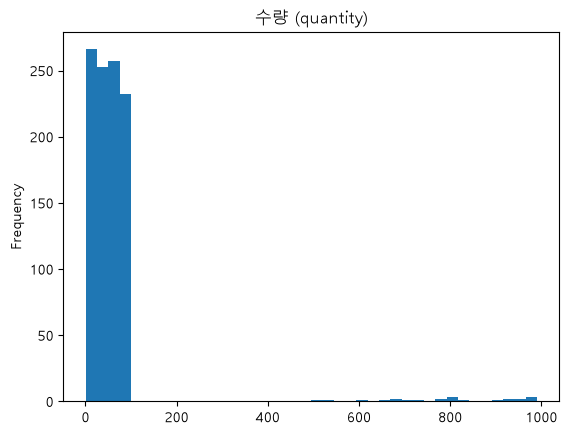

In [11]:
df["quantity"].plot.hist(bins=40, title="수량 (quantity)")
plt.show()

In [12]:
Q1 = df["quantity"].quantile(0.25)
Q3 = df["quantity"].quantile(0.75)
IQR = Q3 - Q1
print("Q1 =", Q1, " Q3 =", Q3, " IQR =", IQR)
print("수염 끝(상한) =", Q3 + 1.5 * IQR)

Q1 = 25.0  Q3 = 75.0  IQR = 50.0
수염 끝(상한) = 150.0


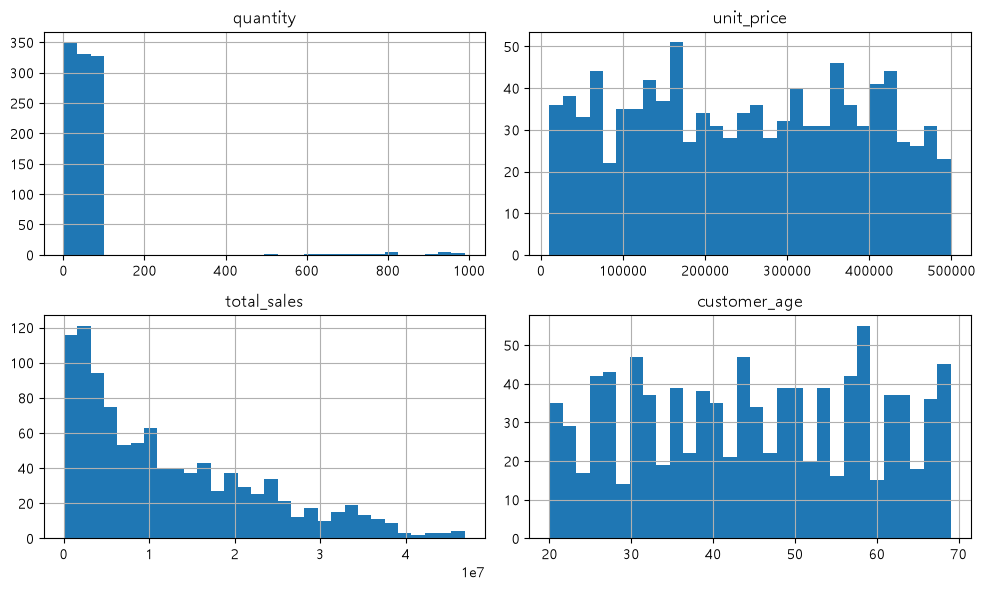

In [13]:
cols = ["quantity", "unit_price",
        "total_sales", "customer_age"]
df[cols].hist(bins=30, figsize=(10, 6))
plt.tight_layout()
plt.show()

In [14]:
dropped = df.dropna(subset=["customer_age"])
print(len(df), "->", len(dropped))

1030 -> 979


In [15]:
age_mean = df["customer_age"].fillna(df["customer_age"].mean())
print("평균  :", round(age_mean.mean(), 3))
print("중앙값:", round(age_mean.median(), 3))
print("최빈값:", round(age_mean.mode()[0], 3))


평균  : 44.858
중앙값: 44.858
최빈값: 44.858


In [16]:
# 결정 : 세 칸의 빈칸은 그대로 둔다
print(df["customer_age"].count(), "/", len(df))

before = len(df)
df = df.drop_duplicates()
print(before, "->", len(df))


979 / 1030
1030 -> 1004


In [17]:
by_iqr  = df["quantity"] > Q3 + 1.5 * IQR   # 통계 규칙 : 상한 150 밖
by_rule = df["quantity"] > 100              # 업무 규칙 : 한 주문 100개 넘지 않는다
print("IQR 규칙 :", by_iqr.sum(), " 업무 규칙 :", by_rule.sum(),
      " 둘이 같은 줄인가 :", (by_iqr == by_rule).all())


IQR 규칙 : 22  업무 규칙 : 22  둘이 같은 줄인가 : True


In [18]:
bad = by_rule
calc = df["quantity"] * df["unit_price"]
diff = (df["total_sales"] - calc).abs()
print("22건 중 금액이 안 맞는 줄 :", (diff[bad] > 1).sum())
ratio = df["total_sales"] / df["unit_price"]
ratio[bad].round(2).head(6)


22건 중 금액이 안 맞는 줄 : 22


31     95.0
188    63.0
273    77.0
316    52.0
334    18.0
361    82.0
dtype: float64

In [19]:
df.loc[bad, "quantity"] = ratio[bad].round().astype(int)
calc = df["quantity"] * df["unit_price"]
diff = (df["total_sales"] - calc).abs()
print("수량 최대 :", df["quantity"].max(), " 불일치 :", (diff > 1).sum())

수량 최대 : 99  불일치 : 0


In [20]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]
df["date_error"].value_counts()


date_error
False    857
True     147
Name: count, dtype: int64

In [21]:
df.to_csv("sales_clean.csv", index=False)
df.shape


(1004, 15)

In [22]:
df[["quantity", "unit_price", "total_sales", "customer_age"]].agg(["mean", "median", "skew"]).round(2)


,quantity,unit_price,total_sales,customer_age
mean,49.41,250146.14,12413727.16,44.90
median,48.00,249449.48,9425457.90,45.00
skew,0.04,0.00,0.94,-0.02


In [23]:
raw = pd.read_csv("sales_data.csv")   # 고치기 전 파일을 다시 읽어 비교
print("수량-총액 상관계수  고치기 전 :", round(raw["quantity"].corr(raw["total_sales"]), 2),
      "  고친 뒤 :", round(df["quantity"].corr(df["total_sales"]), 2))


수량-총액 상관계수  고치기 전 : 0.21   고친 뒤 : 0.67


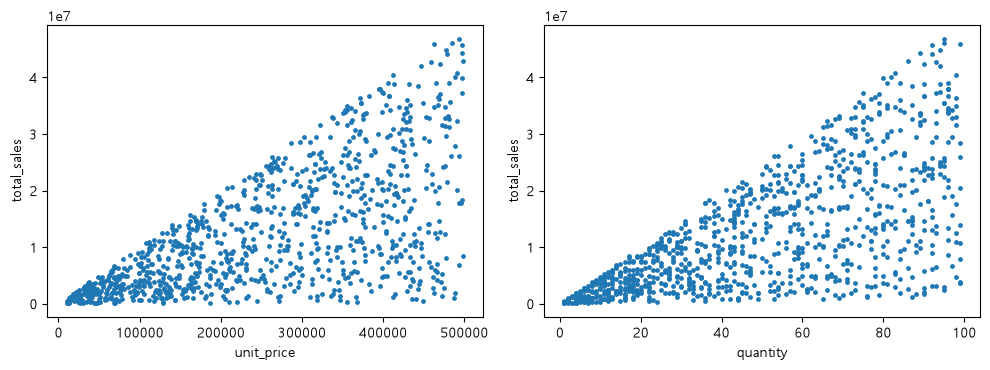

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
df.plot.scatter(x="unit_price", y="total_sales", s=6, ax=ax[0])
df.plot.scatter(x="quantity",   y="total_sales", s=6, ax=ax[1])
plt.tight_layout()
plt.show()


In [25]:
num = ["quantity", "unit_price", "total_sales",
       "customer_age", "satisfaction"]
df[num].corr().round(2)


,quantity,unit_price,total_sales,customer_age,satisfaction
quantity,1.00,0.01,0.67,0.03,0.02
unit_price,0.01,1.00,0.65,-0.07,0.06
total_sales,0.67,0.65,1.00,-0.05,0.06
customer_age,0.03,-0.07,-0.05,1.00,-0.05
satisfaction,0.02,0.06,0.06,-0.05,1.00


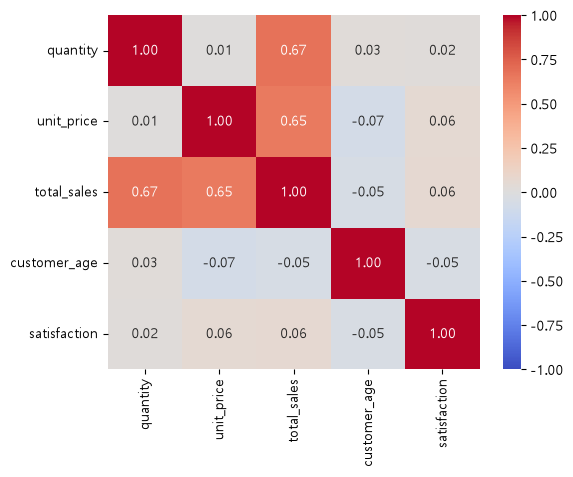

In [26]:
import seaborn as sns

plt.figure(figsize=(6, 4.6))
sns.heatmap(df[num].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0,
            vmin=-1, vmax=1)
plt.show()


In [27]:
by_cat = df.groupby("category")["total_sales"].sum()
(by_cat / 1e8).round(1)   # 억 원 단위


category
가구      28.4
도서      24.5
식품      25.1
의류      21.8
전자제품    24.7
Name: total_sales, dtype: float64

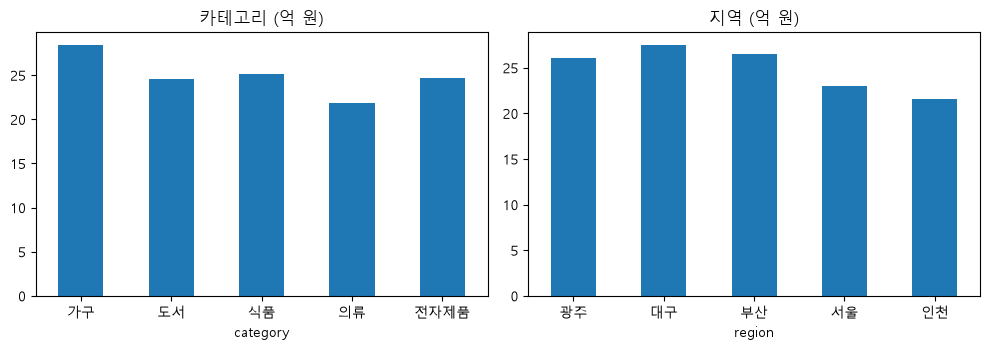

In [28]:
by_reg = df.groupby("region")["total_sales"].sum()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
(by_cat / 1e8).plot.bar(ax=ax[0], title="카테고리 (억 원)", rot=0)
(by_reg / 1e8).plot.bar(ax=ax[1], title="지역 (억 원)", rot=0)
plt.tight_layout()
plt.show()


In [29]:
pv = df.pivot_table(index="region", columns="category",
                    values="total_sales", aggfunc="sum")
(pv / 1e8).round(1)


category,가구,도서,식품,의류,전자제품
region,,,,,
광주,5.1,3.4,5.0,5.4,7.1
대구,7.2,5.0,5.8,4.8,4.7
부산,6.6,5.4,6.8,3.6,4.1
서울,4.4,6.3,3.8,4.2,4.3
인천,5.2,4.3,3.8,3.9,4.4


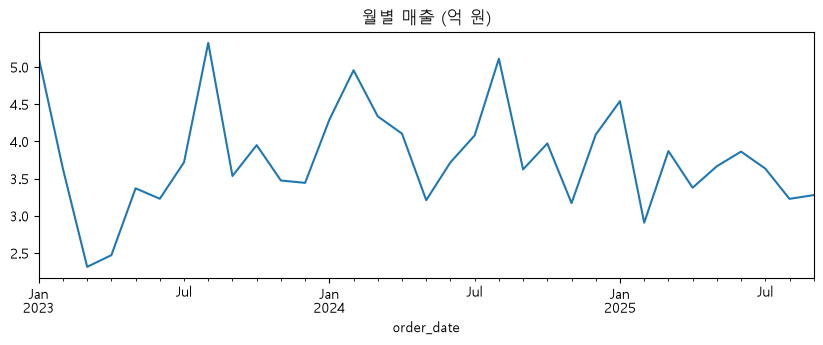

(Period('2023-08', 'M'), np.float64(5.3))

In [30]:
month = df["order_date"].dt.to_period("M")
monthly = df.groupby(month)["total_sales"].sum() / 1e8
monthly.plot(figsize=(10, 3.2), title="월별 매출 (억 원)")
plt.show()
monthly.idxmax(), round(monthly.max(), 1)


## 데이터가 답한 것
- Q1 보통 주문 : 수량 48 개, 943만 원 안팎 (중앙값)
- Q2 매출을 결정하는 것 : 단가 0.65 · 수량 0.67. 나이 · 만족도는 0.1 이내
- Q3 카테고리 · 지역 · 달 차이는 작음 : 가구 28.4억 ~ 의류 21.8억
